# Policy learning: whom to treat?

An average effect says whether a treatment works on average. A policy says *whom* to treat. Given a
doubly robust score $\Gamma_i(a)$ of every unit under every action $a$ (an estimate of its potential
outcome), the value of a treatment rule $\pi$ is

$$
V(\pi) = E[\Gamma(\pi(X))],
$$

and the best rule in a class maximises the sample analogue (Athey and Wager, 2021). Shallow decision
trees are the usual class: they are easy to read and to apply. `dml_rs.OptimalPolicyTree` finds the
best tree of a given depth by exhaustive search, a port of R's `policytree` that finds the same
trees. `dml_rs.policy_value` estimates and compares the values of rules.

This notebook uses the 401(k) data of Chernozhukov and Hansen (2004): net financial assets of 9,915
households and their eligibility for an employer's 401(k) plan. Suppose that making a household
eligible has a cost, the equivalent of \$5,000 of net financial assets per household. Whom should an
employer, or a policy, make eligible?

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dml_rs

warnings.filterwarnings(
    "ignore", message="Bad certificate"
)  # Windows certificate store, while downloading
pd.set_option("display.precision", 1)

df = dml_rs.datasets.fetch_401K(return_type="DataFrame")
covariates = [
    "age",
    "inc",
    "educ",
    "fsize",
    "marr",
    "twoearn",
    "db",
    "pira",
    "hown",
]
X, y, d = df[covariates], df["net_tfa"], df["e401"]

## Doubly robust scores

`APOS` estimates the average potential outcome of each treatment level. Its scores are cross-fitted,
and `double_robust_scores` turns them into the matrix $\Gamma$: one row per household, one column
per level,

$$
\Gamma_i(a) = \hat g(a, X_i) + \frac{1\{D_i = a\}}{\hat P(D = a \mid X_i)} \bigl(Y_i - \hat g(a, X_i)\bigr).
$$

The column means are the average potential outcomes. Subtract the cost from the treated column.

In [2]:
apos = dml_rs.APOS(
    dml_rs.HistGradientBoostingRegressor(),
    dml_rs.HistGradientBoostingClassifier(),
    treatment_levels=[0, 1],
).fit(X, y, d)
gamma = dml_rs.double_robust_scores(apos)
print(
    "average potential outcomes:",
    gamma.mean(axis=0).round(0),
    "  ATE:",
    round(np.diff(gamma.mean(axis=0))[0]),
)

cost = 5000.0
gamma_net = gamma - np.array([0.0, cost])

average potential outcomes: [13886. 21847.]   ATE: 7961


The average effect of eligibility, about \$8,000, exceeds the cost. So making everyone eligible beats
making no one eligible. The question is whether a targeted rule does better still.

## Learn on one half, evaluate on the other

A rule fitted to some units overstates its own value on them. So learn the tree on half of the
households and estimate its value on the other half. The scores are cross-fitted on the full sample,
as in `policytree`'s workflow.

In [3]:
rng = np.random.default_rng(0)
idx = rng.permutation(len(y))
learn, test = idx[: len(y) // 2], idx[len(y) // 2 :]

tree = dml_rs.OptimalPolicyTree(depth=2, min_node_size=100).fit(
    X.to_numpy()[learn], gamma_net[learn]
)


def show(tree, names, actions=("not eligible", "eligible")):
    # Print the tree's rules from its breadth-first node list.
    def walk(i, depth):
        node = tree.nodes_[i]
        pad = "    " * depth
        if node["is_leaf"]:
            print(f"{pad}-> {actions[node['action']]}")
            return
        name, value = names[node["split_variable"]], node["split_value"]
        print(f"{pad}{name} <= {value:g}:")
        walk(node["left"], depth + 1)
        print(f"{pad}{name} > {value:g}:")
        walk(node["right"], depth + 1)

    walk(0, 0)


show(tree, covariates)

educ <= 16:
    inc <= 29019:
        -> not eligible
    inc > 29019:
        -> eligible
educ > 16:
    fsize <= 2:
        -> eligible
    fsize > 2:
        -> not eligible


`nodes_` is the tree as a list of dicts, and `predict` gives the recommended action. Now compare the
tree with the two simple rules on the held-out half. `policy_value` returns a `Framework`. All
policies are evaluated on the same units, so their differences have correct standard errors.

In [4]:
n_test = len(test)
values = dml_rs.policy_value(
    gamma_net[test],
    tree=tree.predict(X.to_numpy()[test]),
    treat_all=np.ones(n_test, dtype=int),
    treat_none=np.zeros(n_test, dtype=int),
)
print(
    "share made eligible by the tree:",
    f"{tree.predict(X.to_numpy()[test]).mean():.0%}"
)
values.summary[["coef", "std err", "2.5 %", "97.5 %"]]

share made eligible by the tree: 52%


,coef,std err,2.5 %,97.5 %
tree,18550.2,1637.5,15340.8,21759.7
treat_all,17126.1,1822.8,13553.4,20698.7
treat_none,14687.3,1252.6,12232.4,17142.3


In [5]:
gains = values.linear_combination(
    np.array([[1.0, -1.0, 0.0], [1.0, 0.0, -1.0]])
)
table = gains.summary[["coef", "std err", "2.5 %", "97.5 %"]]
table.index = ["tree − treat all", "tree − treat none"]
table

,coef,std err,2.5 %,97.5 %
tree − treat all,1424.2,1156.9,-843.4,3691.7
tree − treat none,3862.9,1718.1,495.5,7230.2


The tree makes about half of the households eligible. It clearly beats making no one
eligible. Against making everyone eligible, its gain of about \$1,400 per household is within
sampling noise. The split on income is the expected one: lower-income households save little even
when eligible. The other splits are less certain, and the held-out comparison is the honest check.

## How the rule depends on the cost

A higher cost leaves fewer households for whom eligibility pays. Refit the tree for several costs
and evaluate each on the held-out half:

In [6]:
rows = []
for c in [0, 2500, 5000, 7500, 10000, 15000]:
    g = gamma - np.array([0.0, c])
    t = dml_rs.OptimalPolicyTree(depth=2, min_node_size=100).fit(
        X.to_numpy()[learn], g[learn]
    )
    a = t.predict(X.to_numpy()[test])
    fw = dml_rs.policy_value(
        g[test],
        tree=a,
        treat_all=np.ones(n_test, dtype=int),
        treat_none=np.zeros(n_test, dtype=int),
    )
    best_simple = 1 if fw.coef_[1] >= fw.coef_[2] else 2
    gain = fw.linear_combination(
        np.eye(3)[[0]] - np.eye(3)[[best_simple]]
    )
    rows.append(
        {
            "cost": c,
            "% eligible": 100 * a.mean(),
            "gain over best simple rule": gain.coef_[0],
            "se": gain.se_[0],
        }
    )
by_cost = pd.DataFrame(rows).set_index("cost")
by_cost

,% eligible,gain over best simple rule,se
cost,,,
0,92.1,487.0,882.2
2500,85.0,311.3,640.5
5000,51.9,1424.2,1156.9
7500,42.2,3267.6,1672.5
10000,37.7,2376.4,1584.4
15000,21.0,1202.5,1482.8


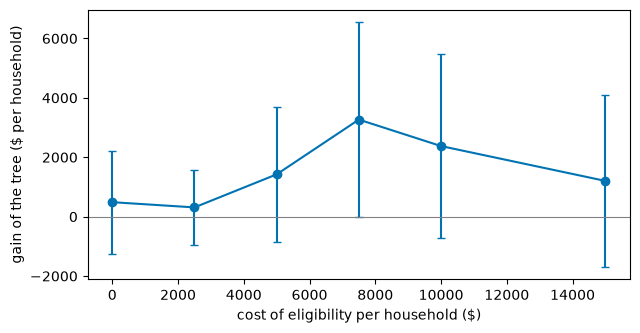

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(
    by_cost.index,
    by_cost["gain over best simple rule"],
    yerr=1.96 * by_cost["se"],
    fmt="o-",
    color="#0173B2",
    capsize=3,
)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("cost of eligibility per household ($)")
ax.set_ylabel("gain of the tree ($ per household)");

Targeting matters most when the cost is close to the average effect. Then about half of the households
gain and half lose, and treating everyone or no one throws away the most. When the cost is far from
the average effect in either direction, one of the simple rules is already close to optimal.

## Practical notes

- **Depth and cost.** The search is exact, so its cost grows like $(p\,n)^{\text{depth}}$. Depth 2 on
  thousands of units and tens of features takes seconds. For depth 3, use `split_step` (consider only
  every k-th split) or fewer features. `min_node_size` keeps leaves large enough to be credible.
- **Several actions.** `Gamma` can have any number of columns, for example from an `APOS` with three
  treatment levels. The tree then picks one of them in each leaf.
- **Greedy trees.** The `policy_tree` methods of `IRM` and `APO` fit a greedy weighted
  classification tree (as DoubleML does). It scales to larger problems but is not optimal.